<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_18_Token_prediction_accuracy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

from datasets import load_dataset

# Part 1: Token prediction

## Task_1:
- Import GPT-2 and its tokenizer.
Tokenize the sentence “Cubism is an art movement that sparked
innovations in music and architecture” and print out a table of its
tokens and token indices.
Run a forward pass and extract the logits for token position
index 5 (starting from an index of 0, so this is actually the 6th token
position), find the token with the maximum logit, and visualize as in
Figure 4.10.
Determine whether the model prediction is accurate. Consider
whether the analysis is incomplete because it’s based on raw logit
values instead of softmax probabilities.

In [2]:
tokenizer=AutoTokenizer.from_pretrained('gpt2')
model=AutoModelForCausalLM.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [3]:
model.eval()

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [4]:
text = 'Cubism is an art movement that sparked innovations in music and architecture'
tokens=tokenizer.encode(text,return_tensors='pt')

for t in tokens[0]:
  print(f'Token {t:5} is "{tokenizer.decode(t)}"')

Token 43632 is "Cub"
Token  1042 is "ism"
Token   318 is " is"
Token   281 is " an"
Token  1242 is " art"
Token  3356 is " movement"
Token   326 is " that"
Token 16752 is " sparked"
Token 25438 is " innovations"
Token   287 is " in"
Token  2647 is " music"
Token   290 is " and"
Token 10959 is " architecture"


In [5]:
with torch.no_grad():
  outputs=model(tokens)

In [6]:
whichToken=5
token_logits=outputs.logits[0,whichToken,:]
maxlogit=torch.argmax(token_logits)

In [8]:
token_logits,maxlogit

(tensor([-102.2299, -101.4537, -111.4774,  ..., -115.5174, -112.9102,
         -104.7822]),
 tensor(326))

In [11]:
tokenizer.decode(maxlogit)

' that'

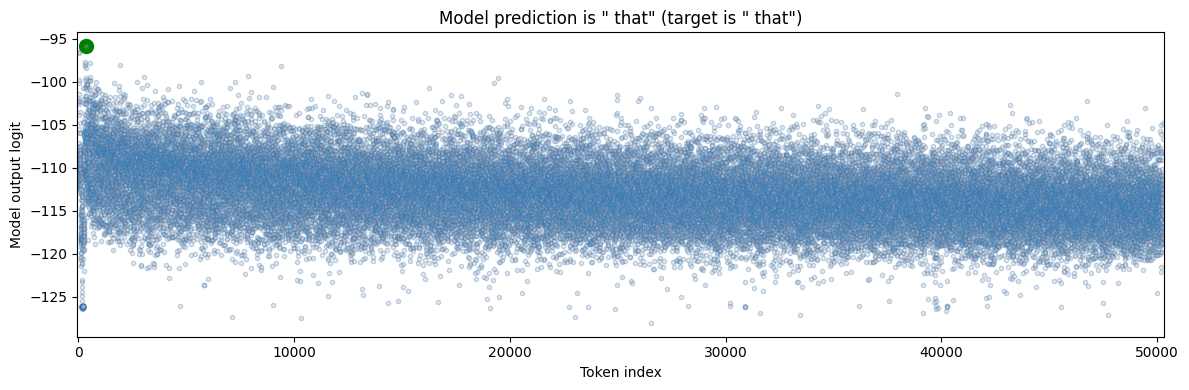

In [9]:
plt.figure(figsize=(12,4))
plt.plot(maxlogit,token_logits[maxlogit],'go',markersize=10)
plt.plot(token_logits,'.',markerfacecolor=[.9,.7,.7,.3])

plt.gca().set(title=f'Model prediction is "{tokenizer.decode(maxlogit)}" (target is "{tokenizer.decode(tokens[0,whichToken+1])}")',
              xlabel='Token index',ylabel='Model output logit',xlim=[-50,tokenizer.vocab_size+49])

plt.tight_layout()
plt.show()

# Part 2: Per-token predictions

## Text_1:
- Loop over all tokens in the sentence and repeat the analysis imple
mented in Part 1. Print the sentence with the predicted token in
serted using quotes. Indicate whether each prediction is correct (✓)
or incorrect (X), and report the average accuracy